## Parcels fieldset.from_NEMO using Glorysv12 w fixed, with adaptive sub-stepping at solid boundaries

In [1]:
num_particles = 100
run_time_days = 20
time_step_minutes = 20
out_put_step_hours = 6

#initial position
# -50.0 -49.08333206176758 -0.08333330601453781 1.1665860414505005
# -49.75, -48.33,-0.17,1.33
lon0 = -49.916
lon1 = -49.083
lat0 = 1.166
lat1 = -0.0833
#
depth_min = 0 #todo: figure near-surface depths 
depth_max = 7

offset = 300
ref_date = "1993-01-01"
#reproducibility
rdm_seed = 11098723
#paths
pathUVW= '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW'
pathTS = "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/tracers"
Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"

In [2]:
# Parameters
num_particles = 100


In [3]:
# --- release polygon: green band (from release_polygon_map.ipynb) ---
#   A  Amazon coast  - start of the old release line
#   B  Para coast    - old line prolonged SE until it strikes the Para bank
#   B' seaward corner off B  (pushed NE, not perpendicular: the Maranhao coast
#                             bends east, so a perpendicular corner runs aground)
#   A' seaward corner off A  (0.8 deg perpendicular)
vertices = {
    "A":  (-49.916,  1.166),   # Amazon coast  - start of release line
    "B":  (-49, -0.16),
    "B'": (-48.3,-0.2),
    "C":  (-48.5,-0.75),
    "C'": (-48.45,-1.05),
    "D":  (-48.12, -0.73 ),   # Para coast    - line prolonged SE to Para bank
    "D'": (-47.8,   -0.6  ),   # seaward corner off B (pushed NE)
    "A'": (-49.250,  1.610),   # seaward corner off A (0.8 deg perpendicular)
}

# build the closed ring (repeat the first point at the end)
_pts = list(vertices.values())
green_lons = [p[0] for p in _pts] + [_pts[0][0]]
green_lats = [p[1] for p in _pts] + [_pts[0][1]]

In [4]:
import numpy as np

In [ ]:
out_path = f'tracks_adaptive_{rdm_seed}/' #path to store the particle zarr

start_time = np.datetime64(ref_date) + np.timedelta64(offset, "D")
start_time

np.datetime64('1993-10-28')

In [6]:
import pandas as pd
start_time = pd.to_datetime(start_time)
t_plus_2y = start_time + pd.DateOffset(years=2)

st_yr = str(start_time)[0:4]
end_yr = str(t_plus_2y)[0:4]

print(st_yr)
print(end_yr)

1993
1995


## Particles from the ARP to the Atlantic

In [7]:
from parcels import ParticleSet
from parcels import JITParticle
# from parcels import ScipyParticle
from parcels import AdvectionRK4_3D
from parcels import AdvectionRK4
from parcels import Variable
from datetime import timedelta
import numpy as np
from parcels import FieldSet
from glob import glob

In [8]:
np.random.seed(rdm_seed)

In [9]:
from pathlib import Path
import os

def files_span(base, prefix, st_yr, end_yr, suffix='c.nc'):
    # all months from Jan st_yr to Dec end_yr
    months = pd.period_range(f'{st_yr}-01', f'{end_yr}-12', freq='M')
    pats = [Path(base) / f"{prefix}_{p.year}-{p.month:02d}{suffix}" for p in months]
    # keep only existing files
    return [str(p) for p in pats if p.exists()]

ufiles = files_span(pathUVW, 'U', st_yr, end_yr, 'c.nc')
vfiles = files_span(pathUVW, 'V', st_yr, end_yr, 'c.nc')
wfiles = files_span(pathUVW, 'W', st_yr, end_yr, 'fc.nc') 
tfiles = files_span(pathTS,  'T', st_yr, end_yr, 'c.nc')
sfiles = files_span(pathTS,  'S', st_yr, end_yr, 'c.nc')

In [10]:
## define the fieldset
filenames = {
    "U": {
        "data":ufiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
    
    "V": {
        "data": vfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
    
    "W": {
        "data": wfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },

    "T": {
        "data": tfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0], #Changed to Wfiles instead of tfiles
    },#on the t points

    "S": {
        "data": sfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0], #Changed to Wfiles instead of tfiles
    }
}


variables = {
    "U": "vozocrtx",
    "V": "vomecrty",
    "W": "vovecrtz",
    "T": "votemper",
    "S": "vosaline",
}

interp_method = {
    "U":"cgrid_velocity",
    "V":"cgrid_velocity",
    "W":"cgrid_velocity",
    "T":"cgrid_velocity",
    "S":"cgrid_velocity",
}


dimensions = {
    "U": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "V": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "W": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "T": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "S": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
}


## now the fieldset
fieldset = FieldSet.from_nemo(
    filenames, 
    variables, 
    dimensions,
    # interp_method = interp_method,
    # tracer_interp_method="cgrid_tracer",
    deferred_load=True,
    allow_time_extrapolation = False,
    # gridindexingtype = "nemo",
)


In [11]:
# --- carve the land out of the release band, using the model's own mask ---
#
# Land in the UVW files is NaN, but parcels replaces NaN with 0 when it loads a
# field (Field._rescale_and_set_minmax), so a particle seeded on land does not
# raise an error - it just sits in zero velocity forever. There is no parcels
# option to refuse a land seed, so the band itself has to exclude land.
#
# mbathy (Zgr) is the number of wet levels at each T point, i.e. NEMO's own land
# mask. Keep a T cell only if its column holds depth_max, then intersect the
# band with the union of those cells. The result follows the model coastline,
# not the Natural Earth one, which is what actually decides where particles sit.
import xarray as xr
from shapely.geometry import Polygon
from shapely.ops import unary_union

_h  = xr.open_dataset(Hgr)
_z  = xr.open_dataset(Zgr)
glamf = _h.glamf.isel(t=0).values          # f points = cell corners
gphif = _h.gphif.isel(t=0).values
mbathy = _z.mbathy.isel(t=0).values        # wet levels per T column (0 = land)
depthw = xr.open_dataset(wfiles[0]).depthw.values

kmin = int(np.searchsorted(depthw, depth_max))   # levels needed to hold depth_max
band = Polygon(zip(green_lons[:-1], green_lats[:-1]))
bl, bs, br, bn = band.bounds

# index window around the band, so we only walk a few hundred cells
_in = (glamf >= bl-0.2) & (glamf <= br+0.2) & (gphif >= bs-0.2) & (gphif <= bn+0.2)
_j, _i = np.where(_in)
j0, j1, i0, i1 = _j.min(), _j.max(), _i.min(), _i.max()

# NEMO/parcels convention: T cell (j,i) has corners f(j-1,i-1)..f(j,i)
wet_cells = []
for j in range(j0+1, j1+1):
    for i in range(i0+1, i1+1):
        if mbathy[j, i] < kmin:
            continue
        q = Polygon([(glamf[j-1, i-1], gphif[j-1, i-1]), (glamf[j-1, i], gphif[j-1, i]),
                     (glamf[j,   i  ], gphif[j,   i  ]), (glamf[j,   i-1], gphif[j,   i-1])])
        if q.intersects(band):
            wet_cells.append(q)

wet_band = band.intersection(unary_union(wet_cells))
if wet_band.geom_type == 'MultiPolygon':                 # keep the main lobe
    wet_band = max(wet_band.geoms, key=lambda g: g.area)

wet_lons, wet_lats = np.array(wet_band.exterior.coords).T
print(f"band {band.area:.3f} deg^2 -> wet band {wet_band.area:.3f} deg^2 "
      f"({100*wet_band.area/band.area:.1f}% kept, {len(wet_lons)-1} vertices)")


band 1.778 deg^2 -> wet band 1.775 deg^2 (99.8% kept, 20 vertices)


In [12]:
# uniform seeding inside the wet band (rejection sampling in its bounding box)
from shapely.geometry import Point
from shapely.prepared import prep

_wb = prep(wet_band)
wl, ws, wr, wn = wet_band.bounds

start_lon = np.empty(num_particles)
start_lat = np.empty(num_particles)
n = 0
while n < num_particles:
    batch = max(num_particles - n, 1) * 3          # over-sample, most fall outside
    x = np.random.uniform(wl, wr, size=batch)
    y = np.random.uniform(ws, wn, size=batch)
    keep = np.fromiter((_wb.contains(Point(a, b)) for a, b in zip(x, y)),
                       dtype=bool, count=batch)
    x, y = x[keep], y[keep]
    take = min(len(x), num_particles - n)
    start_lon[n:n+take] = x[:take]
    start_lat[n:n+take] = y[:take]
    n += take

start_depth = np.random.uniform(depth_min, depth_max, size=num_particles)
start_times = np.datetime64(start_time)


In [13]:
# sanity check: ask parcels itself whether any seed landed on a dry cell.
# Land velocities are zeroed on load, so an exactly-zero UVW means a dry cell.
fieldset.computeTimeChunk(fieldset.U.grid.time[0], 1)
_t = fieldset.U.grid.time[0]
_dry = sum(fieldset.UVW[_t, d, la, lo] == (0.0, 0.0, 0.0)
           for lo, la, d in zip(start_lon, start_lat, start_depth))
print(f"{_dry}/{num_particles} particles seeded on land")
assert _dry == 0, "some particles are on land - widen kmin or check the mask"


0/100 particles seeded on land


In [14]:
def SampleTS(particle, fieldset, time):
    # z = particle.depth
    # Optional: clamp depth to tracer range if needed
    # zmin, zmax can be added as constants if you want; otherwise omit.
    particle.temp = fieldset.T[time, particle.depth, particle.lat, particle.lon]
    particle.sal  = fieldset.S[time, particle.depth, particle.lat, particle.lon]

In [15]:
class SampleParticle(JITParticle):
    """
    Add variables to the standard particle class.
    Sampling temperature, salinity and age of the particle.
    """

    temp = Variable("temp", dtype=np.float32,initial=np.nan)
    sal = Variable("sal", dtype=np.float32,initial=np.nan)
    nrefine = Variable("nrefine", dtype=np.int32, initial=0)   # sub-steps redone with half the step (cumulative)
    ndry = Variable("ndry", dtype=np.int32, initial=0)         # sub-steps taken although in a zero-velocity cell (should stay 0)
    # age = Variable("age", dtype=np.float32,initial=0.0)

In [16]:
pset = ParticleSet(
    fieldset=fieldset,
    pclass = SampleParticle,
    lon = start_lon,
    lat = start_lat,
    depth=start_depth,
    time=start_times
) 

out_fn = f'Parcels_run_{rdm_seed}_{start_time}.zarr'

output_file = pset.ParticleFile(
    name=out_path+out_fn,
    outputdt=timedelta(hours=out_put_step_hours),
    chunks = (num_particles,int(run_time_days*24/out_put_step_hours/4))
)

In [17]:
##check the error
def CheckError(particle, fieldset, time):
    if particle.state >= 50:  # This captures all Errors
        particle.delete()

In [18]:
import math

# RK4-3D with sub-stepping at solid boundaries, done inside the kernel (no StatusCode.Repeat, particle.dt stays constant).
# A trial step whose RK4 stages or end point fall in a cell with u = v = w = 0 (ground) is not taken:
# the sub-step h is halved and recomputed (down to fieldset.dt_min); after an accepted sub-step h doubles back.
def AdvectionRK4_3D_substep(particle, fieldset, time):
    lon0 = particle.lon
    lat0 = particle.lat
    dep0 = particle.depth
    t = time
    remaining = particle.dt
    h = particle.dt
    while remaining > 1e-6:
        if h > remaining:
            h = remaining
        (u1, v1, w1) = fieldset.UVW[t, dep0, lat0, lon0, particle]
        lon1 = lon0 + u1 * 0.5 * h
        lat1 = lat0 + v1 * 0.5 * h
        dep1 = dep0 + w1 * 0.5 * h
        (u2, v2, w2) = fieldset.UVW[t + 0.5 * h, dep1, lat1, lon1, particle]
        lon2 = lon0 + u2 * 0.5 * h
        lat2 = lat0 + v2 * 0.5 * h
        dep2 = dep0 + w2 * 0.5 * h
        (u3, v3, w3) = fieldset.UVW[t + 0.5 * h, dep2, lat2, lon2, particle]
        lon3 = lon0 + u3 * h
        lat3 = lat0 + v3 * h
        dep3 = dep0 + w3 * h
        (u4, v4, w4) = fieldset.UVW[t + h, dep3, lat3, lon3, particle]
        dlon = (u1 + 2 * u2 + 2 * u3 + u4) / 6 * h
        dlat = (v1 + 2 * v2 + 2 * v3 + v4) / 6 * h
        ddep = (w1 + 2 * w2 + 2 * w3 + w4) / 6 * h
        (u5, v5, w5) = fieldset.UVW[t + h, dep0 + ddep, lat0 + dlat, lon0 + dlon, particle]
        dry = 0
        if u2 == 0 and v2 == 0 and w2 == 0:
            dry = 1
        if u3 == 0 and v3 == 0 and w3 == 0:
            dry = 1
        if u4 == 0 and v4 == 0 and w4 == 0:
            dry = 1
        if u5 == 0 and v5 == 0 and w5 == 0:
            dry = 1
        if u1 == 0 and v1 == 0 and w1 == 0:
            dry = 2   # already in a zero-velocity cell: a smaller step cannot help
        if dry == 1 and h > fieldset.dt_min:
            h = h / 2
            particle.nrefine += 1
        else:
            lon0 = lon0 + dlon
            lat0 = lat0 + dlat
            dep0 = dep0 + ddep
            t = t + h
            remaining = remaining - h
            if dry > 0:
                particle.ndry += 1
            h = h * 2
    particle_dlon += lon0 - particle.lon  # noqa
    particle_dlat += lat0 - particle.lat  # noqa
    particle_ddepth += dep0 - particle.depth  # noqa


fieldset.add_constant("dt_min", 1.0)   # smallest sub-step [s]

In [19]:
## Execute particles
pset.execute(
    [SampleTS,AdvectionRK4_3D_substep,CheckError],
    runtime=timedelta(days=run_time_days),
    dt=timedelta(minutes=time_step_minutes),
    output_file= output_file
)

INFO: Output files are stored in tracks_TS_adaptive_11098723/Parcels_run_11098723_1993-10-28 00:00:00.zarr.



  0%|          | 0/1728000.0 [00:00<?, ?it/s]


  0%|          | 1200.0/1728000.0 [00:04<1:59:35, 240.64it/s]


  1%|▏         | 21600.0/1728000.0 [00:05<05:22, 5297.72it/s]


  2%|▎         | 43200.0/1728000.0 [00:09<04:58, 5652.16it/s]


  4%|▍         | 64800.0/1728000.0 [00:10<03:18, 8377.26it/s]

... (76 outputs left out)


 98%|█████████▊| 1686000.0/1728000.0 [02:31<00:10, 4112.45it/s]


 99%|█████████▉| 1706400.0/1728000.0 [02:31<00:03, 6055.15it/s]


100%|██████████| 1728000.0/1728000.0 [02:33<00:00, 7291.97it/s]


100%|██████████| 1728000.0/1728000.0 [02:33<00:00, 11240.44it/s]

## Plotting

In [20]:
import xarray as xr

In [ ]:
out_path = f'tracks_adaptive_{rdm_seed}/'
# out_fn = 'Parcels_run_692' 

ds_traj = xr.open_zarr(out_path+out_fn)
# ds_traj = ds_traj.compute()
ds_traj = ds_traj.compute()
ds_traj

<xarray.Dataset> Size: 449kB
Dimensions:     (trajectory: 100, obs: 80)
Coordinates:
  * obs         (obs) int32 320B 0 1 2 3 4 5 6 7 8 ... 72 73 74 75 76 77 78 79
  * trajectory  (trajectory) int64 800B 0 1 2 3 4 5 6 7 ... 93 94 95 96 97 98 99
Data variables:
    lat         (trajectory, obs) float64 64kB 0.7715 0.7907 ... 0.5863 0.6166
    lon         (trajectory, obs) float64 64kB -49.17 -49.19 ... -49.61 -49.62
    ndry        (trajectory, obs) float64 64kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    nrefine     (trajectory, obs) float64 64kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    sal         (trajectory, obs) float32 32kB 30.67 30.7 29.86 ... 29.05 29.02
    temp        (trajectory, obs) float32 32kB 28.83 28.83 28.9 ... 29.5 29.51
    time        (trajectory, obs) datetime64[ns] 64kB 1993-10-28 ... 1993-11-...
    z           (trajectory, obs) float64 64kB 2.298 2.305 2.304 ... 17.48 17.66
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleSampleTSAdvectionRK4_3D_substepChec...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

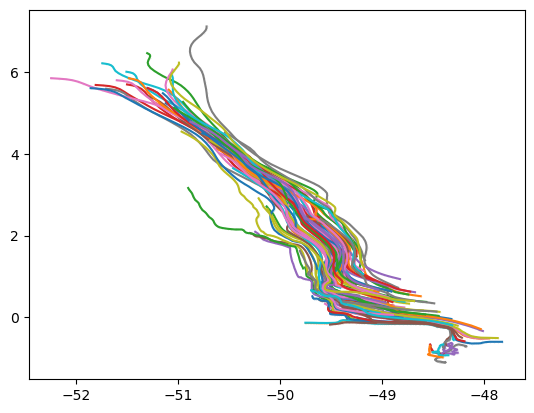

In [22]:
import matplotlib.pyplot as plt
for ii in range(100):
    plt.plot(ds_traj.isel(trajectory=ii).lon.data, ds_traj.isel(trajectory=ii).lat.data,marker='.',markersize=0.1)


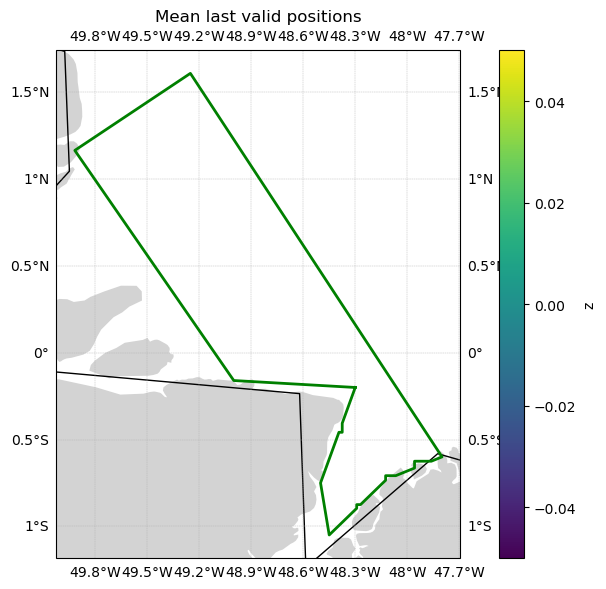

In [23]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

last_valid = ds_traj.lat.notnull().astype(int).diff('obs', label='lower') == -1
ends = ds_traj.where(last_valid).mean('obs').compute()

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.coastlines(resolution='110m')
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)

ends.plot.scatter(
    x='lon',
    y='lat',
    hue='z' if 'z' in ends else None,
    cmap='viridis',
    s=30,
    ax=ax,
    transform=ccrs.PlateCarree()
)

ax.plot(wet_lons, wet_lats, color='green', lw=2)

plt.title('Mean last valid positions')
plt.tight_layout()
plt.show()

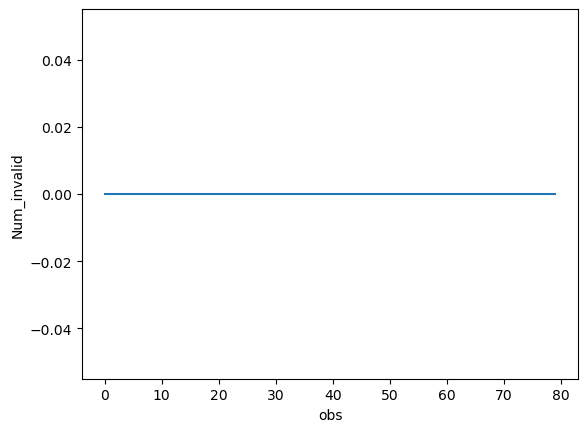

In [24]:
import matplotlib.pyplot as plt
ds_traj.lat.isnull().sum('trajectory').rename('Num_invalid').plot()
plt.show()